# K-Nearest Neighbours (KNN) from Scratch – ML Lab

## 1. What is KNN?

K-Nearest Neighbours (KNN) is a supervised learning algorithm used for classification and regression.

For classification, KNN:
1. Calculates the distance from a new sample to every training sample.
2. Finds the K smallest distances.
3. Looks at the labels of those K neighbours.
4. Predicts the class with the most votes.

Example: if K = 5 and the nearest labels are `[0, 1, 1, 1, 2]`, the prediction is class `1`.

KNN is called a **lazy learning algorithm** because it stores the training data instead of learning a weight matrix during training.

In this notebook, we use a real dataset, scale its features, implement KNN using NumPy, evaluate it using sklearn metrics, compare K values, and predict a new sample.

**Restriction followed:** We do not use sklearn's `KNeighborsClassifier`. The KNN algorithm is implemented from scratch. sklearn is used only for loading the dataset, splitting, scaling, and metrics.


## 2. Import libraries

NumPy is used for distance calculations. Pandas is used to inspect the data. Matplotlib is used for plots. sklearn provides the real dataset and permitted utility functions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score


## 3. Load a real dataset: Wine

The Wine dataset contains 178 wine samples, 13 numerical features, and 3 target classes (cultivars).

Features include alcohol, malic acid, ash, magnesium, color intensity, and proline.

`load_wine(as_frame=True)` loads an existing dataset. It does not generate synthetic data.

In [2]:
wine_data = load_wine(as_frame=True)

X = wine_data.data
y = wine_data.target

df = X.copy()
df["target"] = y

df.head()


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## 4. Understand the dataset

Use `head()`, `shape`, `info()`, `describe()`, and `value_counts()` to inspect the data.

In [3]:
print("Shape:", df.shape)

print("\\nDataset information:")
df.info()

print("\\nStatistical description:")
display(df.describe())

print("\\nClass counts:")
print(df["target"].value_counts().sort_index())


Shape: (178, 14)
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 n

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


\nClass counts:
target
0    59
1    71
2    48
Name: count, dtype: int64


## 5. Handle missing values and duplicates

We remove rows with a missing target and remove duplicate rows. The Wine dataset is already clean, but these are useful data-preparation steps.

Then we separate the features and target.

In [4]:
df = df.dropna(subset=["target"])
df = df.drop_duplicates()

X = df.drop("target", axis=1)
y = df["target"].astype(int)

print("Final dataset shape:", df.shape)


Final dataset shape: (178, 14)


## 6. Train-test split

We use 80% for training and 20% for testing.

`stratify=y` keeps approximately the same proportion of each class in both sets. `random_state=42` makes the split reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (142, 13)
X_test: (36, 13)
y_train: (142,)
y_test: (36,)


## 7. Standardize the features

**Scaling is very important for KNN** because KNN uses distances.

A feature with large values can dominate the distance calculation. For example, Proline can have values in the hundreds or thousands, while Alcohol is around 10 to 15.

StandardScaler uses:

\[
x_{scaled}=\frac{x-\mu}{\sigma}
\]

Here, \(\mu\) is the feature mean and \(\sigma\) is its standard deviation.

Fit the scaler only on training data. Transform both training and test data using that fitted scaler. This prevents data leakage.

In [6]:
scaler = StandardScaler()

X_train_array = scaler.fit_transform(X_train)
X_test_array = scaler.transform(X_test)

print("Training array shape:", X_train_array.shape)
print("Testing array shape:", X_test_array.shape)


Training array shape: (142, 13)
Testing array shape: (36, 13)


## 8. KNN mathematics

### 8.1 Euclidean distance

For two samples with \(n\) features:

\[
d(x,y)=\sqrt{\sum_{j=1}^{n}(x_j-y_j)^2}
\]

Example:

\[
A=[2,3], \quad B=[5,7]
\]

\[
d(A,B)=\sqrt{(2-5)^2+(3-7)^2}
=\sqrt{9+16}=\sqrt{25}=5
\]

A smaller distance means the samples are closer.

For this Wine dataset, the distance is calculated across all 13 features.

### 8.2 Find the K nearest neighbours

Suppose the distances to five training samples are:

\[
[4.2,\ 1.1,\ 3.5,\ 0.8,\ 2.0]
\]

If K = 3, we select the three smallest distances: 0.8, 1.1, and 2.0.

`np.argsort(distances)` returns the indices that arrange the distances in ascending order. We select the first K indices.

### 8.3 Majority voting

Suppose the nearest labels are:

\[
[0,1,1,2,1]
\]

- Class 0 gets one vote.
- Class 1 gets three votes.
- Class 2 gets one vote.

The predicted class is 1.

`np.bincount()` counts the occurrences of each non-negative integer label. `np.argmax()` returns the index with the largest count.

### 8.4 Choosing K

- Small K can be sensitive to noise and individual samples.
- Large K considers more neighbours and can make the model too general.
- We compare different K values to see how the accuracy changes.

An odd K can help avoid ties in binary classification. A tie can still occur with multiple classes.


In [7]:
# Example: Euclidean distance between two points.

point_A = np.array([2, 3])
point_B = np.array([5, 7])

distance = np.sqrt(np.sum((point_A - point_B) ** 2))

print("Euclidean distance:", distance)


Euclidean distance: 5.0


## 9. Implement KNN from scratch

The class has two methods:

- `fit(X, y)`: stores the training features and labels. KNN does not learn weights during fitting.
- `predict(X)`: calculates distances and performs majority voting for each supplied sample.

For each test sample:
1. Calculate its distance from every training sample.
2. Find the K smallest distances.
3. Get the corresponding training labels.
4. Predict the most common label.

We use loops to keep each step easy to follow.

In [8]:
class KNNScratch:
    def __init__(self, k=5):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        # Store the training data.
        self.X_train = X
        self.y_train = y

        return self

    def predict(self, X):
        predictions = []

        # Process one test sample at a time.
        for x in X:

            # Calculate distance to every training sample.
            distances = np.sqrt(
                np.sum((self.X_train - x) ** 2, axis=1)
            )

            # Find the indices of the K smallest distances.
            nearest_indices = np.argsort(distances)[:self.k]

            # Get the labels of the nearest neighbours.
            nearest_labels = self.y_train[nearest_indices]

            # Count the votes for each class.
            class_counts = np.bincount(nearest_labels)

            # Select the class with the most votes.
            prediction = np.argmax(class_counts)

            predictions.append(prediction)

        return np.array(predictions)


## 10. Understand the dimensions and `axis=1`

For this dataset, the training data has 13 feature columns.

For one test sample:
- `self.X_train` has shape `(number_of_training_samples, 13)`.
- `x` has shape `(13,)`.
- `self.X_train - x` has one difference for each training sample and each feature.
- `np.sum(..., axis=1)` adds the squared differences across the 13 features of each training sample.
- `distances` therefore contains one distance per training sample.

`axis=1` means sum across each row. We need one distance for each training row.

Example dimensions (the exact sample count follows the split):

| Variable | Shape | Meaning |
|---|---:|---|
| `X_train_array` | `(142, 13)` | Training features |
| `y_train` | `(142,)` | Training labels |
| `x` | `(13,)` | One sample |
| `self.X_train - x` | `(142, 13)` | Feature differences |
| `distances` | `(142,)` | One distance per training sample |
| `nearest_indices` | `(5,)` | Indices of five nearest samples |
| `nearest_labels` | `(5,)` | Their class labels |


## 11. Train and make predictions

We begin with K = 5. `fit()` stores the training data. `predict()` calculates distances and votes for each sample.

In [9]:
model = KNNScratch(k=5)

model.fit(X_train_array, y_train.to_numpy())

train_predictions = model.predict(X_train_array)
test_predictions = model.predict(X_test_array)

print("First five predictions:", test_predictions[:5])
print("First five actual labels:", y_test.to_numpy()[:5])


First five predictions: [0 2 0 1 1]
First five actual labels: [0 2 0 1 1]


## 12. Evaluate the model

We use sklearn metrics:
- Accuracy: fraction of predictions that are correct.
- Precision: how many predictions for a class are correct.
- Recall: how many actual samples of a class are identified correctly.
- F1 score: harmonic mean of precision and recall.

Weighted averaging combines class-wise metrics according to the number of true samples in each class.

In [10]:
print("Accuracy:", accuracy_score(y_test, test_predictions))

print("Precision:", precision_score(
    y_test, test_predictions, average="weighted", zero_division=0
))

print("Recall:", recall_score(
    y_test, test_predictions, average="weighted", zero_division=0
))

print("F1 Score:", f1_score(
    y_test, test_predictions, average="weighted", zero_division=0
))


Accuracy: 0.9722222222222222
Precision: 0.9747474747474748
Recall: 0.9722222222222222
F1 Score: 0.9723691945914168


## 13. Confusion matrix

Rows represent actual classes. Columns represent predicted classes. Diagonal values are correct predictions; off-diagonal values are mistakes.

Confusion Matrix:
[[12  0  0]
 [ 0 13  1]
 [ 0  0 10]]


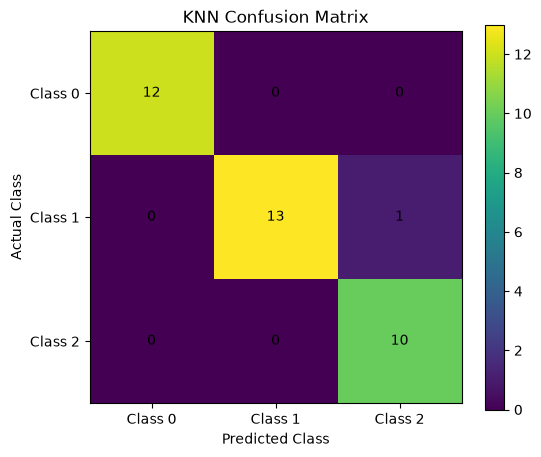

In [11]:
cm = confusion_matrix(y_test, test_predictions)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1, 2], ["Class 0", "Class 1", "Class 2"])
plt.yticks([0, 1, 2], ["Class 0", "Class 1", "Class 2"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()


## 14. Classification report

The report shows precision, recall, F1 score, and support for each class. Support is the number of actual test samples belonging to that class.

In [12]:
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      0.93      0.96        14
           2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



## 15. Compare different K values

We train and evaluate models with different values of K using the same train-test split.

In [13]:
k_values = [1, 3, 5, 7, 9, 11, 13]
accuracy_values = []

for k in k_values:
    model = KNNScratch(k=k)

    model.fit(X_train_array, y_train.to_numpy())

    predictions = model.predict(X_test_array)

    accuracy = accuracy_score(y_test, predictions)
    accuracy_values.append(accuracy)

    print("K:", k, "Accuracy:", accuracy)


K: 1 Accuracy: 0.9722222222222222
K: 3 Accuracy: 0.9722222222222222
K: 5 Accuracy: 0.9722222222222222
K: 7 Accuracy: 1.0
K: 9 Accuracy: 1.0
K: 11 Accuracy: 1.0
K: 13 Accuracy: 1.0


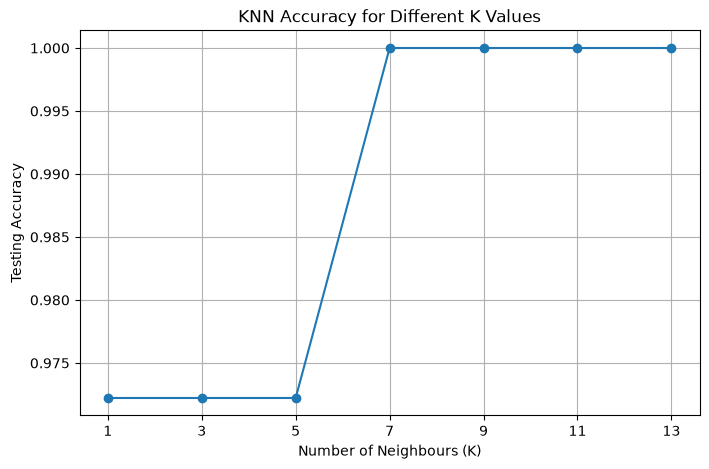

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracy_values, marker="o")

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Testing Accuracy")
plt.title("KNN Accuracy for Different K Values")
plt.xticks(k_values)
plt.grid()

plt.show()


## 16. Predict a new wine sample

The values below are illustrative feature measurements for demonstrating the prediction workflow.

The feature names and order must match the training data. We use the already fitted scaler; we do not fit it again.

In [15]:
# Provide one sample with the same 13 features and their original order.
new_wine = pd.DataFrame(
    [[13.0, 2.0, 2.4, 18.0, 100.0, 2.5, 2.5,
      0.3, 1.8, 5.0, 1.0, 3.0, 900.0]],
    columns=X.columns
)

# Apply the training scaler.
new_wine_array = scaler.transform(new_wine)

# Predict the class.
new_prediction = model.predict(new_wine_array)

print("Predicted wine class:", new_prediction[0])


Predicted wine class: 0


## 17. Advantages and limitations

### Advantages
- Simple and easy to understand.
- Can be used for multiclass classification.
- No complex model training process.
- Makes few assumptions about the data distribution.

### Limitations
- Prediction can be slow for large datasets.
- Feature scaling is important.
- Performance depends on the choice of K.
- Irrelevant features can affect distance calculations.
- Noisy or imbalanced data can affect majority voting.

## 18. Important points for the ML lab exam

1. KNN is a supervised learning algorithm.
2. KNN can be used for classification and regression.
3. K is the number of neighbours considered.
4. Euclidean distance measures closeness.
5. `np.argsort()` helps find the nearest neighbours.
6. Majority voting is used for classification.
7. StandardScaler is important because KNN uses distances.
8. KNN is a lazy learning algorithm.
9. `fit()` stores the training data.
10. `predict()` calculates distances and performs voting.

### Important code to remember

```python
distances = np.sqrt(
    np.sum((self.X_train - x) ** 2, axis=1)
)

nearest_indices = np.argsort(distances)[:self.k]
nearest_labels = self.y_train[nearest_indices]

class_counts = np.bincount(nearest_labels)
prediction = np.argmax(class_counts)
```
